In [1]:
import os
import sys
import math
import time
import subprocess
import ctypes.util

started = time.time()

IS_LINUX = sys.platform.startswith("linux")
if IS_LINUX:
    os.environ["MUJOCO_GL"] = "osmesa"
    os.environ["PYOPENGL_PLATFORM"] = "osmesa"
else:
    os.environ["MUJOCO_GL"] = "glfw"

print("1/4 Installing Python packages...")
subprocess.run(
    [
        sys.executable, "-m", "pip", "install",
        "--quiet", "--only-binary=:all:",
        "gymnasium[mujoco]>=1.2,<2",
        "mujoco>=3.3,<4",
        "imageio", "imageio-ffmpeg", "pillow"
    ],
    check=True
)

if IS_LINUX and not ctypes.util.find_library("OSMesa"):
    print("Installing the software-rendering library...")
    subprocess.run(["apt-get", "update", "-qq"], check=True)
    subprocess.run(
        ["apt-get", "install", "-y", "-qq", "libosmesa6", "libgl1"],
        check=True
    )

import numpy as np
import gymnasium as gym
import mujoco
import imageio.v2 as imageio
from PIL import Image, ImageDraw
from IPython.display import display, Video

print(f"Gymnasium {gym.__version__} | MuJoCo {mujoco.__version__}")


class FixedTorsoMass(gym.Wrapper):
    def __init__(self, env, torso_mass_scale=1.0):
        super().__init__(env)

        scale = float(torso_mass_scale)
        if not np.isfinite(scale) or scale <= 0:
            raise ValueError("torso_mass_scale must be finite and positive.")

        raw = env.unwrapped
        model = raw.model

        torso_id = mujoco.mj_name2id(
            model, mujoco.mjtObj.mjOBJ_BODY, "torso"
        )
        if torso_id < 0:
            raise RuntimeError("Could not find the torso body.")

        self.torso_mass_scale = scale
        self.original_torso_mass = float(model.body_mass[torso_id])
        self.original_total_mass = float(model.body_mass.sum())

        if scale != 1.0:
            model.body_mass[torso_id] *= scale
            model.body_inertia[torso_id] *= scale

            mujoco.mj_setConst(model, raw.data)

        self.current_torso_mass = float(model.body_mass[torso_id])
        self.current_total_mass = float(model.body_mass.sum())


def make_env(torso_mass_scale=1.0, render_mode=None):
    base = gym.make(
        "Walker2d-v5",
        render_mode=render_mode,
        width=800,
        height=480,
        max_episode_steps=1000,
    )

    try:
        return FixedTorsoMass(base, torso_mass_scale)
    except Exception:
        base.close()
        raise

1/4 Installing Python packages...
Gymnasium 1.4.0 | MuJoCo 3.17.0


In [11]:
for folder in ("results", "figures", "videos"):
    os.makedirs(folder, exist_ok=True)

import json
import torch
import torch.nn as nn
import pandas as pd

torch.set_num_threads(1)

ALGORITHMS = ["ddpg", "td3", "sac"]
MASS_SCALES = [1.0, 1.5, 1.75, 2.0]
EVAL_SEEDS = list(range(2000, 2020))
REFERENCE_SEEDS = list(range(100, 105))

probe_env = make_env()
state_dim = probe_env.observation_space.shape[0]
action_dim = probe_env.action_space.shape[0]
dt = float(probe_env.unwrapped.dt)
probe_env.close()

print(f"state_dim={state_dim} | action_dim={action_dim} | dt={dt}s")
print(f"{len(ALGORITHMS)} algorithms x {len(MASS_SCALES)} masses x {len(EVAL_SEEDS)} seeds "
      f"= {len(ALGORITHMS) * len(MASS_SCALES) * len(EVAL_SEEDS)} episodes")

state_dim=17 | action_dim=6 | dt=0.008s
3 algorithms x 4 masses x 20 seeds = 240 episodes


In [12]:
class Actor(nn.Module):
  def __init__(self, state_dim, action_dim):
    super().__init__()
    self.network = nn.Sequential(
        nn.Linear(state_dim, 256),
        nn.ReLU(),
        nn.Linear(256, 256),
        nn.ReLU(),
        nn.Linear(256, action_dim),
        nn.Tanh()
    )

  def forward(self, state):
    return self.network(state)


LOG_STD_MIN, LOG_STD_MAX = -20, 2


class GaussianActor(nn.Module):
    def __init__(self, state_dim, action_dim):
        super().__init__()
        self.body = nn.Sequential(
            nn.Linear(state_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 256),
            nn.ReLU(),
        )
        self.mean_head = nn.Linear(256, action_dim)
        self.log_std_head = nn.Linear(256, action_dim)

    def forward(self, state):
        features = self.body(state)
        return torch.tanh(self.mean_head(features))

    def sample(self, state):
        features = self.body(state)
        mean = self.mean_head(features)
        log_std = self.log_std_head(features).clamp(LOG_STD_MIN, LOG_STD_MAX)
        normal = torch.distributions.Normal(mean, log_std.exp())
        raw_action = normal.rsample()
        action = torch.tanh(raw_action)
        log_prob = normal.log_prob(raw_action) - torch.log(1 - action.pow(2) + 1e-6)
        return action, log_prob.sum(dim=-1, keepdim=True)

In [13]:
def load_actor(algo):
    actor = GaussianActor(state_dim, action_dim) if algo == "sac" else Actor(state_dim, action_dim)
    actor.load_state_dict(torch.load(f"models/{algo}_actor.pt", weights_only=True))
    actor.eval()
    return actor


actors = {algo: load_actor(algo) for algo in ALGORITHMS}
for algo, actor in actors.items():
    n_params = sum(p.numel() for p in actor.parameters())
    print(f"Loaded models/{algo}_actor.pt ({type(actor).__name__}, {n_params:,} parameters)")

Loaded ddpg_actor.pt (Actor, 71,942 parameters)
Loaded td3_actor.pt (Actor, 71,942 parameters)
Loaded sac_actor.pt (GaussianActor, 73,484 parameters)


In [14]:
def run_episode(actor, torso_mass_scale, seed):
    env = make_env(torso_mass_scale=torso_mass_scale)
    try:
        obs, _ = env.reset(seed=seed)
        data = env.unwrapped.data
        start_x = float(data.qpos[0])
        heights, pitches, efforts = [], [], []
        total_reward, steps = 0.0, 0
        terminated = truncated = False

        while not (terminated or truncated):
            with torch.no_grad():
                action = actor(torch.as_tensor(obs, dtype=torch.float32)).numpy()
            obs, reward, terminated, truncated, _ = env.step(action)
            total_reward += float(reward)
            steps += 1
            heights.append(float(data.qpos[1]))
            pitches.append(float(data.qpos[2]))
            efforts.append(float(np.mean(action ** 2)))

        survival_s = steps * dt
        distance = float(data.qpos[0]) - start_x
        return {
            "torso_mass_scale": torso_mass_scale,
            "seed": seed,
            "torso_mass_kg": env.current_torso_mass,
            "total_mass_kg": env.current_total_mass,
            "distance_m": distance,
            "survived": not terminated,
            "steps": steps,
            "survival_s": survival_s,
            "avg_speed_mps": distance / survival_s,
            "return": total_reward,
            "mean_height_m": float(np.mean(heights)),
            "mean_pitch_rad": float(np.mean(pitches)),
            "pitch_std_rad": float(np.std(pitches)),
            "mean_effort": float(np.mean(efforts)),
        }
    finally:
        env.close()

In [15]:
print("1. Mass is applied")
for scale in MASS_SCALES:
    env = make_env(torso_mass_scale=scale)
    print(f"   x{scale:<4} torso {env.current_torso_mass:6.3f} kg | total {env.current_total_mass:6.3f} kg")
    env.close()

print("\n2. Determinism")
first = run_episode(actors["td3"], 1.5, EVAL_SEEDS[0])
second = run_episode(actors["td3"], 1.5, EVAL_SEEDS[0])
deterministic = first == second
print(f"   TD3, mass x1.5, seed {EVAL_SEEDS[0]}: {first['distance_m']:+.4f} m vs {second['distance_m']:+.4f} m "
      f"-> {'PASS' if deterministic else 'FAIL'}")

print("\n3. Saved weights reproduce training-notebook results (mass x1.0)")
all_match = True
for algo in ALGORITHMS:
    try:
        with open(f"models/{algo}_reference.json") as f:
            reference = {int(seed): distance for seed, distance in json.load(f).items()}
    except FileNotFoundError:
        print(f"   {algo}: models/{algo}_reference.json not found; run the save cell in bipedal_{algo}.ipynb")
        all_match = False
        continue
    for seed in REFERENCE_SEEDS:
        measured = run_episode(actors[algo], 1.0, seed)["distance_m"]
        match = abs(measured - reference[seed]) < 1e-6
        all_match &= match
        print(f"   {algo:4} seed {seed}: saved {reference[seed]:+8.3f} m | reloaded {measured:+8.3f} m "
              f"-> {'PASS' if match else 'FAIL'}")

print("\nALL CHECKS PASSED" if deterministic and all_match else "\nSOME CHECKS FAILED: fix before running the sweep")

1. Mass is applied
   x1.0  torso  3.665 kg | total 23.677 kg
   x1.5  torso  5.498 kg | total 25.510 kg
   x1.75 torso  6.414 kg | total 26.426 kg
   x2.0  torso  7.330 kg | total 27.342 kg

2. Determinism
   TD3, mass x1.5, seed 2000: +31.1522 m vs +31.1522 m -> PASS

3. Saved weights reproduce training-notebook results (mass x1.0)
   ddpg seed 100: saved  +29.508 m | reloaded  +29.508 m -> PASS
   ddpg seed 101: saved  +31.082 m | reloaded  +31.082 m -> PASS
   ddpg seed 102: saved  +29.835 m | reloaded  +29.835 m -> PASS
   ddpg seed 103: saved   +1.067 m | reloaded   +1.067 m -> PASS
   ddpg seed 104: saved  +28.040 m | reloaded  +28.040 m -> PASS
   td3  seed 100: saved  +35.155 m | reloaded  +35.155 m -> PASS
   td3  seed 101: saved  +32.844 m | reloaded  +32.844 m -> PASS
   td3  seed 102: saved  +29.835 m | reloaded  +29.835 m -> PASS
   td3  seed 103: saved  +33.344 m | reloaded  +33.344 m -> PASS
   td3  seed 104: saved  +18.351 m | reloaded  +18.351 m -> PASS
   sac  seed 1

In [16]:
import time

rows = []
start = time.time()
for algo in ALGORITHMS:
    for scale in MASS_SCALES:
        for seed in EVAL_SEEDS:
            result = run_episode(actors[algo], scale, seed)
            result["algorithm"] = algo
            rows.append(result)
        print(f"{algo:4} x{scale:<4} done | {time.time() - start:.0f}s elapsed")

results = pd.DataFrame(rows)
results.to_csv("results/payload_results.csv", index=False)
print(f"\n{len(results)} episodes saved to results/payload_results.csv")

ddpg x1.0  done | 1s elapsed
ddpg x1.5  done | 2s elapsed
ddpg x1.75 done | 3s elapsed
ddpg x2.0  done | 3s elapsed
td3  x1.0  done | 5s elapsed
td3  x1.5  done | 6s elapsed
td3  x1.75 done | 7s elapsed
td3  x2.0  done | 9s elapsed
sac  x1.0  done | 11s elapsed
sac  x1.5  done | 12s elapsed
sac  x1.75 done | 14s elapsed
sac  x2.0  done | 15s elapsed

240 episodes saved to payload_results.csv


In [17]:
summary = (
    results.groupby(["algorithm", "torso_mass_scale"])
    .agg(
        distance_mean=("distance_m", "mean"),
        distance_std=("distance_m", "std"),
        survival_rate=("survived", "mean"),
        survival_s_mean=("survival_s", "mean"),
        speed_mean=("avg_speed_mps", "mean"),
        height_mean=("mean_height_m", "mean"),
        pitch_mean=("mean_pitch_rad", "mean"),
        pitch_std_mean=("pitch_std_rad", "mean"),
        effort_mean=("mean_effort", "mean"),
    )
    .reset_index()
)

baseline_distance = summary[summary["torso_mass_scale"] == 1.0].set_index("algorithm")["distance_mean"]
summary["distance_vs_baseline"] = summary["distance_mean"] / summary["algorithm"].map(baseline_distance)

summary.to_csv("results/payload_summary.csv", index=False)
display(summary.round(3))

,algorithm,torso_mass_scale,distance_mean,distance_std,survival_rate,survival_s_mean,speed_mean,height_mean,pitch_mean,pitch_std_mean,effort_mean,distance_vs_baseline
0,ddpg,1.00,13.463,9.762,0.10,4.300,2.631,1.090,-0.272,0.413,0.763,1.000
1,ddpg,1.50,7.330,9.347,0.10,3.114,1.441,1.077,-0.273,0.421,0.796,0.544
2,ddpg,1.75,5.993,8.362,0.10,2.834,0.867,1.054,-0.418,0.330,0.795,0.445
3,ddpg,2.00,3.117,6.039,0.00,1.628,0.310,1.029,-0.482,0.308,0.826,0.232
4,sac,1.00,24.373,3.152,0.95,7.784,3.130,1.231,0.164,0.241,0.623,1.000
5,sac,1.50,21.438,7.140,0.65,7.166,2.983,1.200,0.131,0.241,0.627,0.880
6,sac,1.75,20.218,8.111,0.60,6.390,3.043,1.203,0.128,0.251,0.632,0.830
7,sac,2.00,15.415,7.631,0.20,4.860,3.069,1.177,0.120,0.268,0.642,0.632
8,td3,1.00,26.658,12.217,0.60,6.401,3.777,1.135,-0.232,0.264,0.706,1.000
9,td3,1.50,20.941,15.778,0.55,5.301,2.851,1.122,-0.198,0.301,0.733,0.786


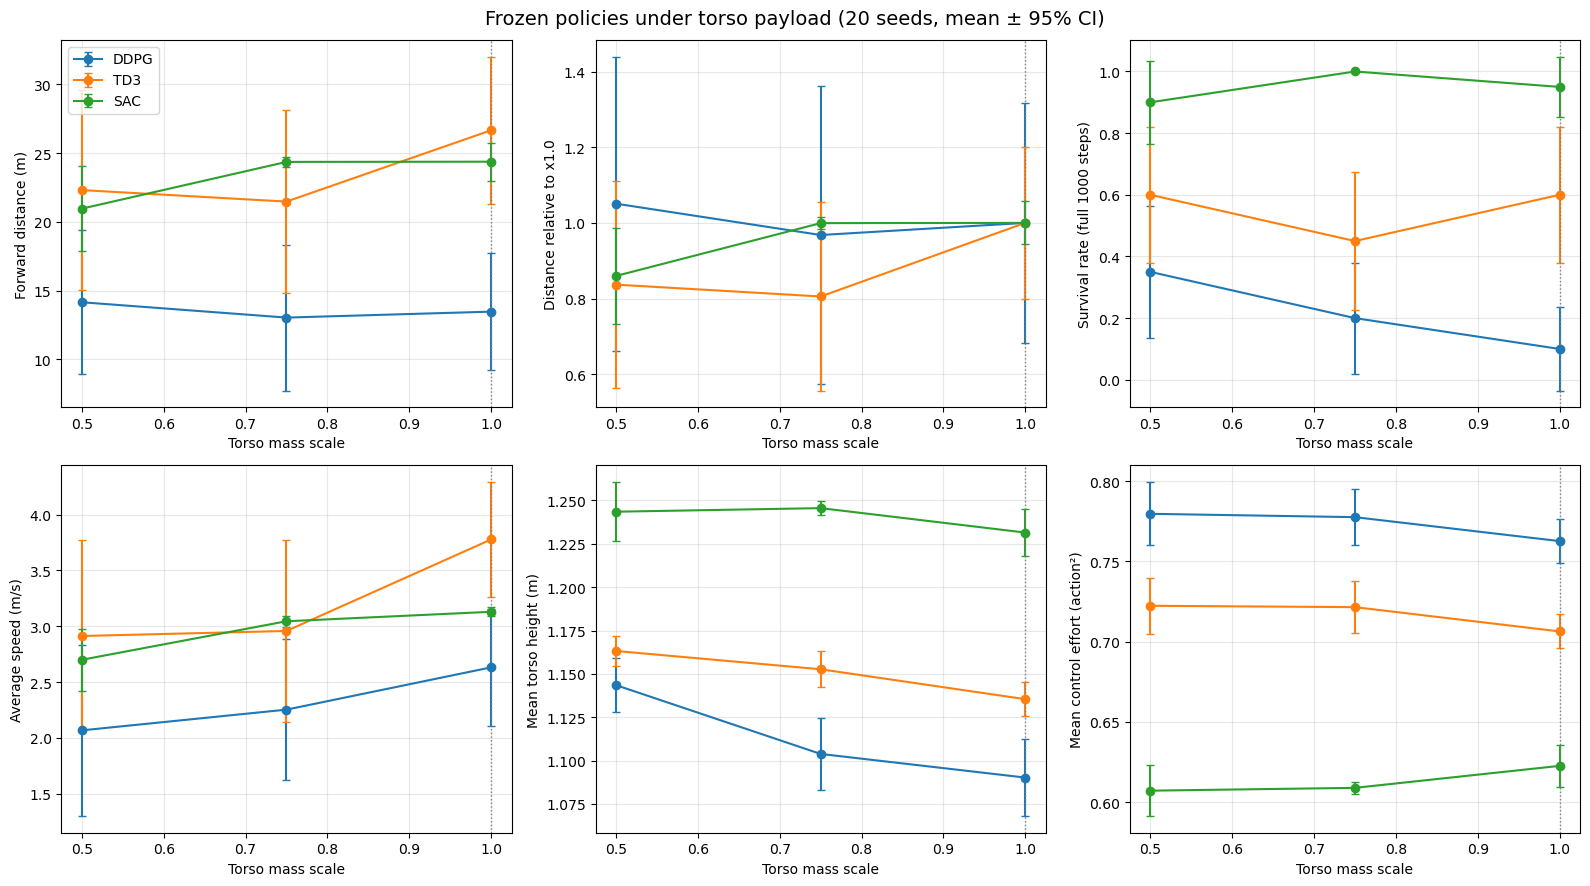

In [9]:
import matplotlib.pyplot as plt

COLORS = {"ddpg": "tab:blue", "td3": "tab:orange", "sac": "tab:green"}
LABELS = {"ddpg": "DDPG", "td3": "TD3", "sac": "SAC"}


def plot_metric(ax, column, ylabel, normalise=False):
    for algo in ALGORITHMS:
        data = results[results["algorithm"] == algo]
        values = data[column].astype(float).groupby(data["torso_mass_scale"])
        mean = values.mean()
        ci95 = 1.96 * values.std() / np.sqrt(values.count())
        if normalise:
            base = mean.loc[1.0]
            mean, ci95 = mean / base, ci95 / base
        ax.errorbar(mean.index, mean.values, yerr=ci95.values, marker="o", capsize=3,
                    color=COLORS[algo], label=LABELS[algo])
    ax.axvline(1.0, color="gray", linestyle=":", linewidth=1)
    ax.set_xlabel("Torso mass scale")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)


fig, axes = plt.subplots(2, 3, figsize=(16, 9))
plot_metric(axes[0, 0], "distance_m", "Forward distance (m)")
plot_metric(axes[0, 1], "distance_m", "Distance relative to x1.0", normalise=True)
plot_metric(axes[0, 2], "survived", "Survival rate (full 1000 steps)")
plot_metric(axes[1, 0], "avg_speed_mps", "Average speed (m/s)")
plot_metric(axes[1, 1], "mean_height_m", "Mean torso height (m)")
plot_metric(axes[1, 2], "mean_effort", "Mean control effort (action²)")
axes[0, 0].legend()
fig.suptitle(f"Frozen policies under torso payload ({len(EVAL_SEEDS)} seeds, mean ± 95% CI)", fontsize=14)
plt.tight_layout()
fig.savefig("figures/payload_results.png", dpi=150)
plt.show()

In [10]:
baseline = (
    results[results["torso_mass_scale"] == 1.0][["algorithm", "seed", "distance_m"]]
    .rename(columns={"distance_m": "baseline_distance_m"})
)
paired = results.merge(baseline, on=["algorithm", "seed"])
paired["distance_change_m"] = paired["distance_m"] - paired["baseline_distance_m"]

paired_summary = (
    paired.groupby(["algorithm", "torso_mass_scale"])["distance_change_m"]
    .agg(mean_change_m="mean", std_change_m="std", n="count", fraction_of_seeds_worse=lambda d: (d < 0).mean())
    .reset_index()
)
paired_summary["ci95_m"] = 1.96 * paired_summary["std_change_m"] / np.sqrt(paired_summary["n"])
paired_summary["significant"] = paired_summary["mean_change_m"].abs() > paired_summary["ci95_m"]

paired_summary.to_csv("results/payload_paired.csv", index=False)
display(paired_summary.round(3))

print("Breaking point (first heavier mass where fewer than half the seeds survive):")
for algo in ALGORITHMS:
    broken = summary[
        (summary["algorithm"] == algo)
        & (summary["torso_mass_scale"] > 1.0)
        & (summary["survival_rate"] < 0.5)
    ]
    if len(broken):
        print(f"  {LABELS[algo]:4}: x{broken['torso_mass_scale'].min()}")
    else:
        print(f"  {LABELS[algo]:4}: survives at least 50% of seeds at every tested mass")

,algorithm,torso_mass_scale,mean_change_m,std_change_m,n,fraction_of_seeds_worse,ci95_m,significant
0,ddpg,0.50,0.683,15.488,20,0.40,6.788,False
1,ddpg,0.75,-0.432,16.904,20,0.55,7.409,False
2,ddpg,1.00,0.000,0.000,20,0.00,0.000,False
3,sac,0.50,-3.417,8.058,20,0.80,3.532,False
4,sac,0.75,-0.015,3.285,20,0.80,1.440,False
5,sac,1.00,0.000,0.000,20,0.00,0.000,False
6,td3,0.50,-4.351,21.552,20,0.60,9.445,False
7,td3,0.75,-5.188,19.835,20,0.60,8.693,False
8,td3,1.00,0.000,0.000,20,0.00,0.000,False


Breaking point (first heavier mass where fewer than half the seeds survive):
  DDPG: survives at least 50% of seeds at every tested mass
  TD3 : survives at least 50% of seeds at every tested mass
  SAC : survives at least 50% of seeds at every tested mass


In [19]:
import imageio.v2 as imageio
from PIL import Image, ImageDraw, ImageFont
from IPython.display import Video, display

VIDEO_SEED = EVAL_SEEDS[0]
STRIDE = 8
TILE_W, TILE_H = 400, 240
GRID_COLS = 3
try:
    FONT = ImageFont.load_default(size=16)
except TypeError:
    FONT = ImageFont.load_default()
video_fps = 1 / (STRIDE * dt)


def record_tiles(actor, scale, seed):
    env = make_env(torso_mass_scale=scale, render_mode="rgb_array")
    tiles = []
    try:
        obs, _ = env.reset(seed=seed)
        data = env.unwrapped.data
        start_x = float(data.qpos[0])
        env.render()
        camera = env.unwrapped.mujoco_renderer.viewer.cam
        camera.azimuth, camera.elevation, camera.distance = 90.0, -10.0, 4.0

        def capture(steps):
            camera.lookat[:] = [data.body("torso").xpos[0], 0.0, 1.0]
            image = Image.fromarray(env.render()).resize((TILE_W, TILE_H))
            tiles.append((image, steps, float(data.qpos[0]) - start_x))

        capture(0)
        steps = 0
        terminated = truncated = False
        while not (terminated or truncated):
            with torch.no_grad():
                action = actor(torch.as_tensor(obs, dtype=torch.float32)).numpy()
            obs, _, terminated, truncated, _ = env.step(action)
            steps += 1
            if steps % STRIDE == 0 or terminated or truncated:
                capture(steps)
        return tiles, bool(terminated)
    finally:
        env.close()


def label_tile(image, algo, scale, steps, distance, fell, finished):
    tile = image.copy()
    draw = ImageDraw.Draw(tile)
    draw.rectangle((0, 0, TILE_W, 26), fill=(22, 26, 34))
    draw.text((8, 4), f"{algo.upper()} x{scale} | {distance:+.1f} m | {steps * dt:.1f}s", fill="white", font=FONT)
    if finished:
        status, color = ("FELL", (255, 90, 90)) if fell else ("FINISHED", (120, 230, 120))
        draw.text((TILE_W - 90, 4), status, fill=color, font=FONT)
    return tile


def make_gait_videos(seed, mass_scales, prefix="payload_walk"):
    grid_rows = -(-len(mass_scales) // GRID_COLS)

    for algo in ALGORITHMS:
        rollouts = {scale: record_tiles(actors[algo], scale, seed) for scale in mass_scales}
        n_frames = max(len(tiles) for tiles, _ in rollouts.values())
        path = f"videos/{prefix}_{algo}.mp4"

        with imageio.get_writer(path, fps=video_fps, codec="libx264", macro_block_size=16) as writer:
            for i in range(n_frames):
                canvas = Image.new("RGB", (GRID_COLS * TILE_W, grid_rows * TILE_H))
                for k, scale in enumerate(mass_scales):
                    tiles, fell = rollouts[scale]
                    last = len(tiles) - 1
                    image, steps, distance = tiles[min(i, last)]
                    tile = label_tile(image, algo, scale, steps, distance, fell, finished=i >= last)
                    canvas.paste(tile, ((k % GRID_COLS) * TILE_W, (k // GRID_COLS) * TILE_H))
                writer.append_data(np.asarray(canvas))

        outcomes = ", ".join(
            f"x{scale}: {'fell' if fell else 'finished'} at {tiles[-1][2]:+.1f} m"
            for scale, (tiles, fell) in rollouts.items()
        )
        print(f"{algo.upper()} (seed {seed}) -> {path}\n  {outcomes}")
        display(Video(path, embed=True, width=900))


make_gait_videos(VIDEO_SEED, MASS_SCALES)

DDPG (seed 2000) -> payload_walk_ddpg.mp4
  x1.0: fell at +0.5 m, x1.5: finished at +29.2 m, x1.75: fell at +7.6 m, x2.0: fell at +9.0 m


TD3 (seed 2000) -> payload_walk_td3.mp4
  x1.0: finished at +35.9 m, x1.5: finished at +31.2 m, x1.75: finished at +35.4 m, x2.0: finished at +34.0 m


SAC (seed 2000) -> payload_walk_sac.mp4
  x1.0: finished at +25.0 m, x1.5: fell at +8.6 m, x1.75: fell at +9.1 m, x2.0: finished at +26.7 m


In [ ]:
import math
import time

SCREEN_SEEDS = list(range(3000, 4000))
N_COMMON = 50
N_PER_ALGO = 100
ROBUST_MASS_SCALES = [1.0, 1.25, 1.5, 1.75, 2.0]
BOOTSTRAP_SAMPLES = 2000
rng = np.random.default_rng(0)


def wilson_interval(successes, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    p = successes / n
    denominator = 1 + z ** 2 / n
    centre = (p + z ** 2 / (2 * n)) / denominator
    half_width = z * math.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / denominator
    return centre - half_width, centre + half_width


def bootstrap_ci(values, statistic=np.mean):
    values = np.asarray(values, dtype=float)
    if len(values) == 0:
        return np.nan, np.nan
    samples = rng.choice(values, size=(BOOTSTRAP_SAMPLES, len(values)), replace=True)
    return tuple(np.percentile(statistic(samples, axis=1), [2.5, 97.5], method="nearest"))

In [ ]:
start = time.time()
screen_rows = []
for algo in ALGORITHMS:
    for seed in SCREEN_SEEDS:
        result = run_episode(actors[algo], 1.0, seed)
        screen_rows.append({
            "algorithm": algo,
            "seed": seed,
            "survived": result["survived"],
            "distance_m": result["distance_m"],
        })
    print(f"{algo:4} screened {len(SCREEN_SEEDS)} seeds | {time.time() - start:.0f}s elapsed")

screen = pd.DataFrame(screen_rows)
screen.to_csv("results/robust_screen.csv", index=False)

print("\nUnscreened survival at x1.0 (report this alongside the screened results):")
for algo in ALGORITHMS:
    survived = screen[screen["algorithm"] == algo]["survived"]
    low, high = wilson_interval(int(survived.sum()), len(survived))
    print(f"  {algo.upper():4} {survived.mean():6.1%}  (95% CI {low:.1%} to {high:.1%}, n={len(survived)})")

qualifying = {
    algo: sorted(screen[(screen["algorithm"] == algo) & screen["survived"]]["seed"])
    for algo in ALGORITHMS
}
common_pool = sorted(set.intersection(*(set(seeds) for seeds in qualifying.values())))
common_seeds = common_pool[:N_COMMON]
per_algo_seeds = {algo: seeds[:N_PER_ALGO] for algo, seeds in qualifying.items()}

print(f"\nSeeds where all three survive x1.0: {len(common_pool)} -> using {len(common_seeds)}")
for algo in ALGORITHMS:
    print(f"  {algo.upper():4} qualifying seeds: {len(qualifying[algo])} -> using {len(per_algo_seeds[algo])}")
if len(common_seeds) < N_COMMON or any(len(s) < N_PER_ALGO for s in per_algo_seeds.values()):
    print("WARNING: fewer qualifying seeds than requested. Widen SCREEN_SEEDS for tighter confidence intervals.")

In [ ]:
start = time.time()
robust_rows = []
common_set = set(common_seeds)
for algo in ALGORITHMS:
    per_algo_set = set(per_algo_seeds[algo])
    seeds = sorted(common_set | per_algo_set)
    for scale in ROBUST_MASS_SCALES:
        for seed in seeds:
            result = run_episode(actors[algo], scale, seed)
            result["algorithm"] = algo
            result["in_common"] = seed in common_set
            result["in_per_algo"] = seed in per_algo_set
            robust_rows.append(result)
        print(f"{algo:4} x{scale:<5} {len(seeds)} seeds | {time.time() - start:.0f}s elapsed")

robust = pd.DataFrame(robust_rows)
robust.to_csv("results/robust_results.csv", index=False)
print(f"\n{len(robust)} episodes saved to results/robust_results.csv")

assert robust[robust["torso_mass_scale"] == 1.0]["survived"].all(), \
    "A qualifying seed fell at x1.0: results are not deterministic, so stop and investigate."
print("Determinism check passed: every qualifying seed survives x1.0 again.")

In [ ]:
import matplotlib.pyplot as plt

COLORS = {"ddpg": "tab:blue", "td3": "tab:orange", "sac": "tab:green"}
LABELS = {"ddpg": "DDPG", "td3": "TD3", "sac": "SAC"}

robust_common = robust[robust["in_common"]]


def plot_robust_metric(ax, column, ylabel, normalise=False):
    for algo in ALGORITHMS:
        data = robust_common[robust_common["algorithm"] == algo]
        values = data[column].astype(float).groupby(data["torso_mass_scale"])
        mean = values.mean()
        ci95 = 1.96 * values.std() / np.sqrt(values.count())
        if normalise:
            base = mean.loc[1.0]
            mean, ci95 = mean / base, ci95 / base
        ax.errorbar(mean.index, mean.values, yerr=ci95.values, marker="o", capsize=3,
                    color=COLORS[algo], label=LABELS[algo])
    ax.axvline(1.0, color="gray", linestyle=":", linewidth=1)
    ax.set_xlabel("Torso mass scale")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)


fig, axes = plt.subplots(2, 3, figsize=(16, 9))
plot_robust_metric(axes[0, 0], "distance_m", "Forward distance (m)")
plot_robust_metric(axes[0, 1], "distance_m", "Distance relative to x1.0", normalise=True)
plot_robust_metric(axes[0, 2], "survived", "Survival rate (full 1000 steps)")
plot_robust_metric(axes[1, 0], "avg_speed_mps", "Average speed (m/s)")
plot_robust_metric(axes[1, 1], "mean_height_m", "Mean torso height (m)")
plot_robust_metric(axes[1, 2], "mean_effort", "Mean control effort (action²)")
axes[0, 0].legend()
fig.suptitle(f"Frozen policies under torso payload ({len(common_seeds)} screened common seeds, mean ± 95% CI)", fontsize=14)
plt.tight_layout()
fig.savefig("figures/robust_payload.png", dpi=150)
plt.show()

In [ ]:
ROBUST_VIDEO_SEED = 3092
ROBUST_VIDEO_MASSES = [1.0, 1.2, 1.4, 1.6, 1.8, 2.0, 2.25, 2.5, 3.0]

make_gait_videos(ROBUST_VIDEO_SEED, ROBUST_VIDEO_MASSES, prefix="robust_walk")